# M05-5 (Optional) | weight_norm in PTQ: Fine Without BN, Remove It First With BN

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/bobondemon/pt2e_quantize_and_deploy/blob/main/en/m05_ptq_pipeline/05_weight_norm_ptq.ipynb)

`torch.nn.utils.parametrize` lets a parameter become "computed from other parameters". `weight_norm` is one example: it replaces `conv.weight` with
$g \cdot v / \lVert v \rVert$ ($g$ is stored in `original0`, $v$ in `original1`), and every access to `conv.weight` recomputes it.
If you are not familiar with parametrize, first read the official [parametrize tutorial](https://docs.pytorch.org/tutorials/intermediate/parametrizations.html)
and the [`weight_norm` docs](https://docs.pytorch.org/docs/2.14/generated/torch.nn.utils.parametrizations.weight_norm.html).
For why weight_norm splits the weight this way and what the gradients of $g$ and $v$ look like, I suggest first reading the blog post "[Notes on Weight Normalization](https://bobondemon.github.io/2022/09/26/Weight-Normalization-%E7%9A%84%E7%AD%86%E8%A8%98/)" (in Chinese). It uses the old `torch.nn.utils.weight_norm`, while this course uses `torch.nn.utils.parametrizations.weight_norm`; the split is the same, only the names under which $g$ and $v$ are stored differ.

- **A.** After export: the weight becomes a computation in the graph.
- **B.** Without BN: prepare and convert both work.
- **C.** With BN: `prepare_pt2e` raises an error when folding BN.
- **D.** Two fixes: remove it on the module before export, or remove it in the graph after export.

For the basic graph-editing moves see M00-4, and for BN folding see M04-1. QAT has to keep weight_norm during training and does it differently; see M06-6.

In [1]:
#| include: false
# When running on Google Colab: download this course's code and install the packages (takes a few minutes the first time).
# When running on your own machine (see the README for the environment), this cell does nothing.
import sys

if "google.colab" in sys.modules:
    import os
    import subprocess

    repo = "/content/pt2e_quantize_and_deploy"
    if not os.path.exists(repo):
        subprocess.run(["git", "clone", "-q", "--depth", "1",
                        "https://github.com/bobondemon/pt2e_quantize_and_deploy.git", repo], check=True)
        subprocess.run([sys.executable, "-m", "pip", "install", "-q",
                        "--extra-index-url", "https://download.pytorch.org/whl/cpu",
                        "torch==2.14.0+cpu", "torchao==0.18.0", "onnx==1.23.0", "onnxscript==0.7.2",
                        "onnxruntime==1.30.0", "tabulate", "graphviz"], check=True)
    sys.path.insert(0, repo)  # lets the notebook import this course's common/
    os.chdir(f"{repo}/en/m05_ptq_pipeline")

In [2]:
import copy

import torch
from torch.nn.utils import parametrize

from common.data import calibration_batches
from common.graph_utils import op_counts
from common.models import ConvBnReLU, ConvReLU, example_inputs
from common.pt2e import convert_pt2e, export_module, get_xnnpack_quantizer, prepare_pt2e, quiet
from common.viz import draw, draw_stages, table
from common.weight_norm import add_weight_norm, strip_weight_norm

quiet()
_ = torch.manual_seed(0)


def make(cls, wrap=True):
    """Small model with BN warmed up on a few batches; with wrap=True, apply weight_norm to conv.weight."""
    torch.manual_seed(0)
    m = cls(3, 8).train()
    with torch.no_grad():
        for _ in range(3):
            m(torch.randn(16, 3, 16, 16))
    m.eval()
    if wrap:
        add_weight_norm(m)
    return m


def ptq(gm, **convert_kwargs):
    """prepare → calibrate on 128 samples → convert; returns (prepared, converted)."""
    prepared = prepare_pt2e(gm, get_xnnpack_quantizer(is_per_channel=True)[0])
    with torch.no_grad():
        for batch in calibration_batches(128):
            prepared(*batch)
    return prepared, convert_pt2e(copy.deepcopy(prepared), **convert_kwargs)


x = torch.randn(8, 3, 16, 16)

`add_weight_norm(model)` is a tool of this project (`common/weight_norm.py`); it is equivalent to calling
`torch.nn.utils.parametrizations.weight_norm(model.conv, dim=0)` on `model.conv`.

## A. After Export: The Weight Becomes a Computation

model parameters: ['conv.bias', 'conv.parametrizations.weight.original0', 'conv.parametrizations.weight.original1']
eval outputs allclose before/after applying weight_norm: True (g is initialized to ‖v‖, so the values are unchanged at first)


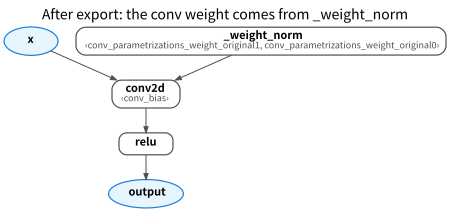

In [3]:
wn = make(ConvReLU)
with torch.no_grad():
    same = torch.allclose(make(ConvReLU, wrap=False)(x), wn(x), atol=1e-6)
print("model parameters:", [n for n, _ in wn.named_parameters()])
print("eval outputs allclose before/after applying weight_norm:", same, "(g is initialized to ‖v‖, so the values are unchanged at first)")
assert same

gm = export_module(copy.deepcopy(wn), example_inputs())
draw(gm, title="After export: the conv weight comes from _weight_norm")

parametrize turns `weight` into a property, and export only traces how forward executes, so the computation $g \cdot v / \lVert v \rVert$ goes into the graph (`aten._weight_norm`).
The real parameters are `original0` ($g$) and `original1` ($v$), written under `_weight_norm`.
Every later step that "does something to the weight" sees this `call_function` node, not a `get_attr`.

## B. Without BN: prepare and convert Both Work

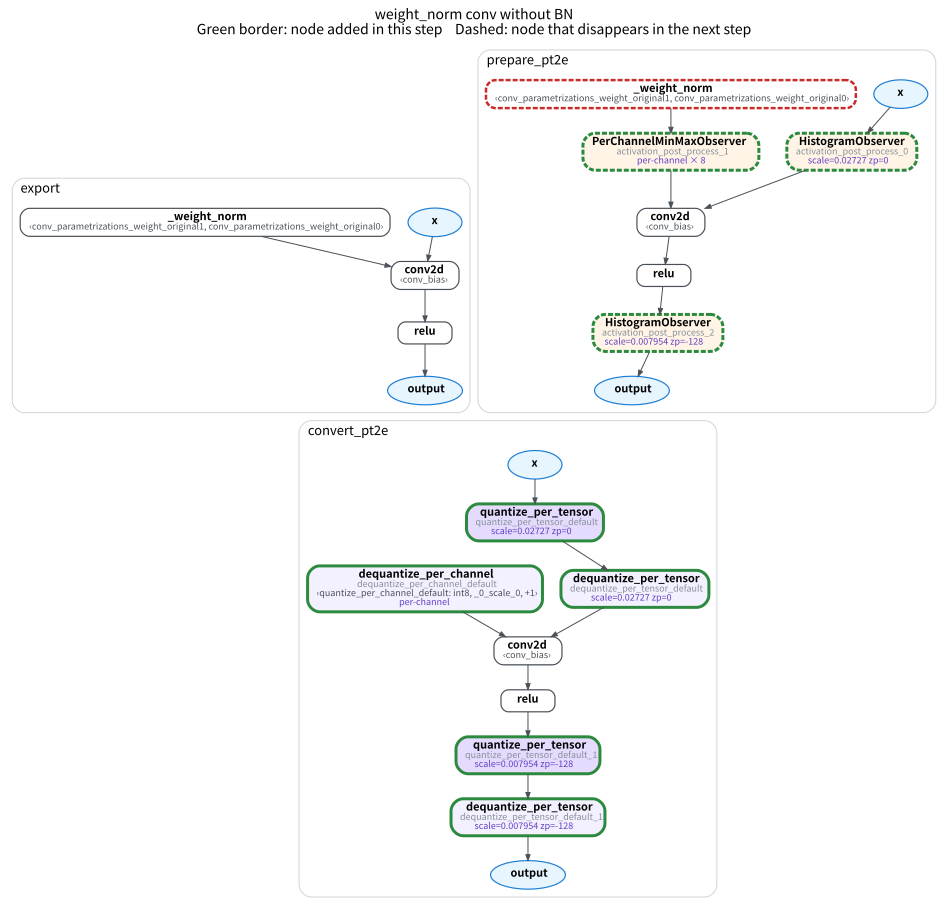

In [4]:
prepared, converted = ptq(copy.deepcopy(gm))
_, no_fold = ptq(copy.deepcopy(gm), fold_quantize=False)
draw_stages([(gm, "export"), (prepared, "prepare_pt2e"), (converted, "convert_pt2e")], title="weight_norm conv without BN")

In [5]:
rows = [["after prepare_pt2e", "_weight_norm" in op_counts(prepared)],
        ["convert_pt2e(prepared)", "_weight_norm" in op_counts(converted)],
        ["convert_pt2e(prepared, fold_quantize=False)", "_weight_norm" in op_counts(no_fold)]]
table(rows, ["which graph", "still has _weight_norm?"])

which graph,still has _weight_norm?
after prepare_pt2e,True
convert_pt2e(prepared),False
"convert_pt2e(prepared, fold_quantize=False)",True


In [6]:
assert [r[1] for r in rows] == [True, False, True]

- After prepare, the weight's observer hangs on the output of `_weight_norm`: what is quantized is "the computed weight", the same as for a regular conv.
- `convert_pt2e` defaults to `fold_quantize=True`, which precomputes quantize ops whose inputs are all constants into int8 constants (M02-3); `_weight_norm`'s inputs are all constants too, so it disappears together with the quantize. With `fold_quantize=False` both stay.

## C. With BN: prepare_pt2e Raises an Error When Folding BN

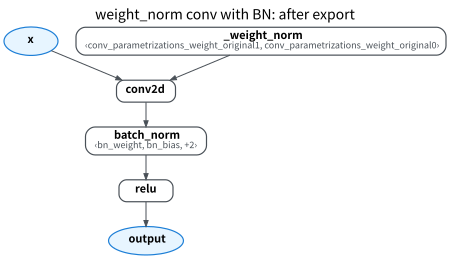

In [7]:
wn_bn = make(ConvBnReLU)
with torch.no_grad():
    y_wn_bn = wn_bn(x)
gm_bn = export_module(copy.deepcopy(wn_bn), example_inputs())
draw(gm_bn, title="weight_norm conv with BN: after export")

In [8]:
try:
    prepare_pt2e(copy.deepcopy(gm_bn), get_xnnpack_quantizer(is_per_channel=True)[0])
    error = None
except ValueError as e:
    error = e
print("prepare_pt2e →", f"{type(error).__name__}: {error}")
assert error is not None

prepare_pt2e → ValueError: Expected get_attr node, got call_function


PTQ folds BN right at the start of `prepare_pt2e` (M04-1): it reads the conv's weight as a constant, multiplies by BN's coefficients, and writes it back.
The function that reads the constant is torchao's internal `_get_tensor_constant_from_node`, which only accepts `get_attr` (from reading the source).
When the weight is a `_weight_norm` `call_function`, it errors out directly instead of silently skipping.

## D. Two Fixes

### Fix 1: Call `remove_parametrizations` on the Module Before Export

`leave_parametrized=True` stores the currently computed weight as a regular parameter, then removes the parametrization:

In [9]:
parametrize.remove_parametrizations(wn_bn.conv, "weight", leave_parametrized=True)
with torch.no_grad():
    same = torch.equal(wn_bn(x), y_wn_bn)
print("parameters after remove_parametrizations:", [n for n, _ in wn_bn.named_parameters()], "; outputs torch.equal:", same)
assert same

parameters after remove_parametrizations: ['conv.weight', 'bn.weight', 'bn.bias'] ; outputs torch.equal: True


This fix has a trap: deepcopy a clone and remove the parametrization only on the **clone**, and the original model breaks too:

In [10]:
orig = make(ConvReLU)
clone = copy.deepcopy(orig)
parametrize.remove_parametrizations(clone.conv, "weight", leave_parametrized=True)
try:
    orig(x)
    trap = None
except AttributeError as e:
    trap = e
print("original model forward →", f"{type(trap).__name__}: {trap}")
assert trap is not None

original model forward → AttributeError: 'ParametrizedConv2d' object has no attribute 'weight'


parametrize replaces the module's `__class__` with a dynamically generated `ParametrizedConv2d`; deepcopy does not copy the class, so the original model and the clone share the same class.
When the parametrization is removed from the clone, the `weight` property is deleted from the shared class, and the original model can no longer find `weight`.

### Fix 2: After Export, Replace `_weight_norm` in the Graph with a Constant

`strip_weight_norm(gm)` is a tool of this project (`common/weight_norm.py`): it computes the weight using the same `_weight_norm` in the graph,
stores it as a new parameter, inserts a `get_attr` node, uses `replace_all_uses_with` to make the conv consume it instead, and then deletes `_weight_norm` (the graph-editing moves of M00-4).

weights stripped: ['conv.weight']


outputs torch.equal before/after strip: True


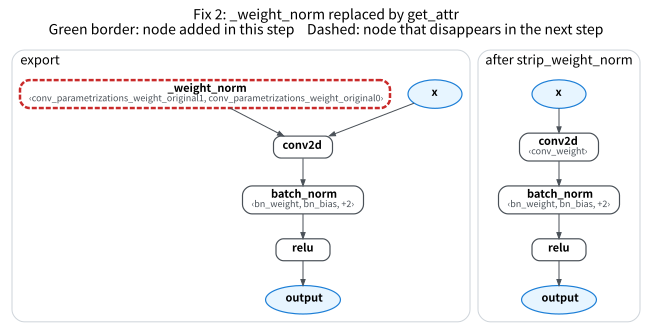

In [11]:
fixed = copy.deepcopy(gm_bn)
print("weights stripped:", strip_weight_norm(fixed))
with torch.no_grad():
    same = torch.equal(fixed(x), gm_bn(x))
print("outputs torch.equal before/after strip:", same)
assert same
draw_stages([(gm_bn, "export"), (fixed, "after strip_weight_norm")], title="Fix 2: _weight_norm replaced by get_attr")

In [12]:
_, c_fixed = ptq(fixed)
print("prepare_pt2e and convert_pt2e both succeed; ops after convert:", dict(op_counts(c_fixed)))
assert "batch_norm" not in op_counts(c_fixed)

prepare_pt2e and convert_pt2e both succeed; ops after convert: {'quantize_per_tensor': 2, 'dequantize_per_tensor': 2, 'dequantize_per_channel': 1, 'conv2d': 1, 'relu': 1}


Fix 2 does not touch `nn.Module`: the conv in the exported graph is an ordinary module, $g$ and $v$ are just parameters under it, and the graph edit changes only this graph, so there is no need to worry about dynamic classes.
PTQ does not train and $g$ and $v$ are of no use anyway, so both fixes work.

## Summary

- Export traces weight_norm's computation into the graph, and the conv's weight becomes `aten._weight_norm`.
- Without BN, PTQ works fine and convert folds it, together with quantize, into a constant; with BN, folding BN in `prepare_pt2e` needs to read a constant and errors out directly.
- PTQ has no use for weight_norm: use `remove_parametrizations` before export (beware of the deepcopy trap), or `strip_weight_norm` after export.
  QAT has to keep $g$ and $v$ during training, and prepare does not fold BN; see M06-6 for the approach.